# Jev-as-a-Judge, LLM-as-a-Judge, and confidence-based escalation

A routing agent assigns an intent to a user's request. When it gets the intent wrong,
we review the mistake and assign a failure category. We focus on **Vague Utterance**:
a routing mistake caused by an ambiguous request or missing information.

We want to automate the check: **“Is this routing result a Vague Utterance failure?”**
Human reviewers have already labeled the examples, so we can compare each judge's
answers with theirs.

We compare three ways to judge the same 300 examples:

| Approach | Who provides the final answer? |
| --- | --- |
| **1. Jev alone** | Jev judges every example. |
| **2. LLM alone** | GPT-4.1-mini judges every example. |
| **3. Jev first, LLM when confidence is low** | Keep Jev's answer when confidence is at least 0.7; otherwise use the LLM's answer. Invalid Jev output also goes to the LLM. |

We first measure Jev and the LLM separately. We then combine them using Jev's confidence
to decide when to ask the LLM, and compare the combined approach with both standalone
approaches.

The notebook includes the completed results. To run the judges again, provide TypeSafe
and OpenAI credentials, or replay a run you previously saved locally. Setup details are
in the [README](../README.md).

## 1. Why bring System 1 thinking to evaluation?

The System 1 / System 2 analogy separates a quick, narrow judgment from more deliberative
reasoning. Jev applies the first idea to software: it returns a typed decision and
probabilities for a question defined by your policy. An LLM can additionally produce a short
explanation, useful when the case needs closer inspection. These are design roles, not a
claim that either model reproduces human cognition or that the LLM always wins.

A repeated, well-defined check is a useful candidate for a cheap first pass. The hypothesis
we will test is that Jev can handle many cases, while an LLM earns its extra cost on the cases
Jev finds uncertain. Whether that works depends on **error detection, complementary
judgments, and measured costs**. Confidence can be high on an incorrect answer.

See [TypeSafe's System One introduction](https://docs.typesafe.ai/introduction).

In [1]:
# Run from this directory, the repository root, or a fresh Colab runtime.
import os, sys, subprocess
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO_REF = os.environ.get("ROUTING_EVALS_REF", "codex/jev-routing-judge")
candidates = [Path.cwd(), Path.cwd() / "routing_agent_evals",
              Path.cwd() / "AI-Evals-Principles/routing_agent_evals"]
LAB = next((p for p in candidates if (p / "judge_lab.py").exists()), None)
if LAB is None and IN_COLAB:
    checkout = Path("/content/routing-evals-lab")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_REF,
                        "https://github.com/The-Gen-Academy/Mastering-Agentic-AI-Week4-Session1.git",
                        str(checkout)], check=True)
    LAB = checkout / "AI-Evals-Principles/routing_agent_evals"
if LAB is None or not (LAB / "judge_lab.py").exists():
    raise RuntimeError("Open the notebook from its repository checkout; see README for setup.")
LAB = LAB.resolve()
os.chdir(LAB)
sys.path.insert(0, str(LAB))
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pandas", "scikit-learn", "matplotlib", "python-dotenv"], check=True)

In [2]:
# Fresh checkouts run live; replay can use your own local run directory.
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dotenv import load_dotenv
from judge_lab import (JudgeClient, batch, load_dataset, request_for,
                       metrics, run_cascade, needs_llm,
                       confidence_bands, always_false, save_json, digest,
                       POLICY, CRITERIA, JEV_MODEL, LLM_MODEL, DEFAULT_PROVIDERS,
                       JUDGE_DATA_SOURCE, CONFIDENCE_THRESHOLD)

load_dotenv(LAB / ".env", override=False)
RUN = Path(os.environ.get("JUDGE_RUN_DIR", str(LAB / ".runs/judge")))
EVIDENCE = Path(os.environ.get("JUDGE_EVIDENCE_DIR", str(RUN)))
DEFAULT_MODE = "replay" if (EVIDENCE / "manifest.json").exists() else "live"
MODE = os.environ.get("JUDGE_MODE", DEFAULT_MODE)
assert MODE in {"replay", "live"}
RUN.mkdir(parents=True, exist_ok=True)
CACHE = EVIDENCE / "cache" if MODE == "replay" else RUN / "cache"
if MODE == "replay" and not (EVIDENCE / "manifest.json").exists():
    raise RuntimeError("No complete benchmark here. Run live with funded judge credentials, then replay that run directory.")
manifest = json.loads((EVIDENCE / "manifest.json").read_text()) if MODE == "replay" else {}
providers = manifest.get("providers", DEFAULT_PROVIDERS) if MODE == "replay" else {
    "jev": os.environ.get("JEV_PROVIDER", "typesafe"),  # or "openrouter"
    "llm": os.environ.get("LLM_PROVIDER", "openai"),  # or "openrouter"
}
client = JudgeClient(CACHE, live=(MODE == "live"), providers=providers,
                     models=manifest.get("models"), pricing=manifest.get("pricing"))
if MODE == "live":
    secrets_by_name = {}
    for stage, name in client.key_names.items():
        key = secrets_by_name.get(name) or os.environ.get(name)
        if not key and IN_COLAB:
            try:
                from google.colab import userdata
                key = userdata.get(name)
            except Exception:
                pass
        if not key:
            from getpass import getpass
            key = getpass(f"{name} (hidden, never saved): ").strip()
        secrets_by_name[name] = key
        client.api_keys[stage] = key
print("Mode:", MODE, "| providers:", client.providers, "| models:", client.models)
print("HTTP 401/402/403 stops the run. Fix that provider's credentials/credits, then resume.")

Mode: replay | providers: {'jev': 'typesafe', 'llm': 'openai'} | models: {'jev': 'jev-1.13.0', 'llm': 'gpt-4.1-mini-2025-04-14'}
HTTP 401/402/403 stops the run. Fix that provider's credentials/credits, then resume.


## 2. From routing mistakes to judge labels

Human reviewers prepared the **LLM as a Judge dataset** in two steps:

1. **Find the mistakes.** Compare the expected intent (`TARGET_INTENT`) with the router's
   prediction (`final_intent`). Of 300 examples, 52 have different intents and are routing
   failures. The other 248 have matching intents.
2. **Categorize the mistakes.** Review those 52 failures and assign a failure category.
   **20 are Vague Utterance failures**; the other **32** belong to categories such as
   Negation Error or False Unsupported.

Because Vague Utterance is the category we care about most, we record a yes/no answer
in `Vague_Utterance_Failure` for each row:

| Human review result | Number of examples | `Vague_Utterance_Failure` |
| --- | ---: | --- |
| Vague Utterance failure | 20 | `TRUE` |
| Another kind of routing failure | 32 | `FALSE` |
| Correctly routed | 248 | `FALSE` |

**Now we ask the models to perform the check.** For each row, we give Jev and the LLM
the user request, the router's predicted intent, and the same rules. Each judge answers:
**“Is this a Vague Utterance failure?”** We then compare its `TRUE` or `FALSE` answer
with the human label in that row.

We give the judges all 300 rows, including correctly routed requests, because a judge
can mistakenly flag a correct result as a Vague Utterance failure. We want to count those
false alarms as well as the failures it finds or misses.

The human answers are hidden from both judges: they do not receive the target intent,
reviewer comments, failure category, or `Vague_Utterance_Failure` label. The LLM also does
not see Jev's answer or confidence.

We use a **fixed confidence cutoff of 0.7** for the Jev-first approach. A valid Jev
answer with confidence at or above 0.7 is kept; a lower-confidence or invalid answer goes
to the LLM. All three approaches are compared on the same **300 rows**. The human labels
are used to measure the results, not to choose the cutoff.

In [3]:
rows = load_dataset(LAB / "data")
display(pd.DataFrame([{"examples": len(rows),
                       "Vague Utterance failures": sum(r["human_label"] == "TRUE" for r in rows),
                       "other examples": sum(r["human_label"] == "FALSE" for r in rows)}]))
display(pd.DataFrame(rows[:3])[["id", "user_query", "predicted_intent", "human_label"]])

,examples,Vague Utterance failures,other examples
0,300,20,280


,id,user_query,predicted_intent,human_label
0,TEST_009,How many patients did I see last month?,IRRELEVANT_QUERY,FALSE
1,TEST_016,Cancel my 10:00 - 10:30 patient Monday,UNSUPPORTED_REQUEST,FALSE
2,TEST_031,I am busy today,UNSUPPORTED_REQUEST,TRUE


The same task rules are sent to both judges. The next cell shows those rules and an
example request, so we can check what information the judges receive.

In [4]:
print("Shared policy:\n", POLICY)
display(pd.DataFrame([{"decision": label, "definition": text} for label, text in CRITERIA.items()]))
sample_request = request_for(rows[0], "jev")
print("State sent to Jev:", sample_request["state"])
assert set(sample_request["state"]) == {"user_query", "predicted_intent"}

Shared policy:
 # Role:
You are an impartial evaluator for an AI scheduling assistant used by doctors.

#Goal:
Your job is to determine whether a misclassification of intent occurred specifically due to “vague utterances.” wherein the request is ambiguous and/or missing key arguments.

# What you will be given
- A chat trace between the doctor (user) and the agent
- The agent’s predicted intent for the doctor’s request (the “model intent”)
- The set of valid intents with definitions (provided below)

# Your task:
1. Identify the  request the agent should act on.
2. Determine the most appropriate gold intent for that request using the intent definitions.
3. Decide whether the agent’s intent classification is wrong.
4. If wrong, decide whether the error is caused by a “vague utterance” (as defined below), versus other causes 

# Definition of “Vague utterances” failure mode

Mark VAGUE_UTTERANCE = True only when:
- User intent could be supported but is ambiguous or missing key arguments,

,decision,definition
0,TRUE,The predicted intent is wrong specifically bec...
1,FALSE,"The predicted intent is correct, or it is wron..."


State sent to Jev: {'user_query': 'How many patients did I see last month?', 'predicted_intent': 'IRRELEVANT_QUERY'}


## 3. Approach 1: Jev alone

First, ask **Jev to judge every example**. Its `TRUE` or `FALSE` choice is the final
answer for this approach. We also record its confidence, which we will use later in
the combined approach.

Jev uses **`type: "choice"`** to select between `TRUE` and `FALSE`. It returns the chosen
label, the probability of each option, and a confidence value. The label answers the
failure-category question; confidence tells us how strongly Jev favors that answer.
Choice returns a category, whereas the Score primitive evaluates ordered rating levels.

### How to read Jev's confidence

Jev assigns a probability to each option, `TRUE` and `FALSE`. The two probabilities add
to 1. The **winning probability** is the probability assigned to the option Jev chooses.

For this two-option Choice, **confidence is the gap between the two probabilities**.
A 50/50 split gives confidence 0 because neither option is favored. A 100/0 split gives
confidence 1 because all the probability is on one option.

For example, suppose Jev returns `TRUE: 0.85` and `FALSE: 0.15`:

- It chooses `TRUE`, whose winning probability is **0.85**.
- Its confidence is **0.85 − 0.15 = 0.70**.

The formula `confidence = 2 × winning_probability − 1` gives the same result: the other
option has probability `1 − winning_probability`, so subtracting it produces this formula.
These numbers describe Jev's own estimates; they do not establish how often it is correct.

[Choice documentation](https://docs.typesafe.ai/primitives/choice) ·
[Confidence definition](https://docs.typesafe.ai/confidence)

In [5]:
jev = batch(rows, lambda r: client.call(r, "jev"))
example = rows[0]
display(pd.DataFrame([jev[example["id"]]]))
display(pd.DataFrame([metrics(rows, jev, "Jev alone")]))

,id,stage,request_hash,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,attempts,elapsed_seconds,input_tokens,output_tokens,label,error,confidence,probabilities,model
0,TEST_009,jev,d508cd78336e6779d69ea84e5711b0df88ae49d4fc178d...,0.000055,0,0.000055,1,0,1,1,0.091085,1320,33,FALSE,None,0.88,"{'TRUE': 0.06, 'FALSE': 0.94}",jev-1.13.0


,method,n,positive_references,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,TN,FP,FN_including_unresolved,TP,unresolved,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,llm_routes
0,Jev alone,300,20,0.893333,0.0,0.0,0,268,12,20,0,0,0.016651,0,0.016651,300,0,300,0


## 4. Approach 2: LLM alone

Next, ask **GPT-4.1-mini to judge every example**. Its answer is final for this approach.
It uses the same 300 examples and task rules as Jev, and does not see Jev's answers.
This shows how the LLM performs on its own.

Its response contains a `label` and a brief `reason`, allowing us to inspect each judgment.
A JSON schema validates the response format. Comparing the label with the human answer
checks the judgment itself. We use temperature zero to reduce variation between runs,
though identical settings do not guarantee identical answers.

We now have results for each judge on its own. The next approach combines them: Jev
judges first, and its confidence determines whether to ask this same LLM judge.

In [6]:
llm = batch(rows, lambda r: client.call(r, "llm"))
display(pd.DataFrame([llm[example["id"]]]))
display(pd.DataFrame([metrics(rows, values, name) for name, values in
                      [("Always FALSE", always_false(rows)),
                       ("Jev alone", jev), ("LLM alone", llm)]]))

,id,stage,request_hash,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,attempts,elapsed_seconds,input_tokens,output_tokens,label,error,reason,model
0,TEST_009,llm,f57bea4d2c89c52fb80306f7fb27e095cf803a33d704d6...,0.000508,0,0.000508,1,0,1,1,2.890816,1042,57,FALSE,None,The user's query is clearly about viewing past...,gpt-4.1-mini-2025-04-14


,method,n,positive_references,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,TN,FP,FN_including_unresolved,TP,unresolved,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,llm_routes
0,Always FALSE,300,20,0.933333,0.000000,0.00,0.00000,280,0,20,0,0,0.000000,0,0.000000,0,0,0,0
1,Jev alone,300,20,0.893333,0.000000,0.00,0.00000,268,12,20,0,0,0.016651,0,0.016651,300,0,300,0
2,LLM alone,300,20,0.776667,0.178082,0.65,0.27957,220,60,7,13,0,0.153302,0,0.153302,300,0,300,0


## 5. Approach 3: Jev first, LLM when confidence is low

Now combine the two judges. **Start with Jev for every example**, then use its confidence
to decide whose answer to keep. This approach uses Jev for confident decisions and the
LLM for cases that need another judgment.

The policy is simple: **keep a valid Jev judgment when confidence ≥ 0.7; otherwise ask
the LLM.** Invalid Jev output also goes to the LLM. If the LLM fails, record the case as
unresolved for human review. A failed second call does not make the rejected Jev answer
more trustworthy.

| Jev result | What happens next |
| --- | --- |
| Valid label and confidence ≥ 0.7 | Keep Jev's label. |
| Valid label and confidence < 0.7 | Ask the LLM independently. |
| Invalid output | Ask the LLM independently. |
| LLM also fails | Record an unresolved case for human review. |

**What does the 0.7 cutoff mean?** For our two choices, confidence is the gap between
Jev's probabilities for `TRUE` and `FALSE`. We keep its answer when that gap is at least 0.7:

| Probability of chosen option | Probability of other option | Confidence (the gap) | Action |
| ---: | ---: | ---: | --- |
| 0.70 | 0.30 | 0.40 | Ask the LLM. |
| 0.85 | 0.15 | 0.70 | Keep Jev's answer. |
| 0.95 | 0.05 | 0.90 | Keep Jev's answer. |

That is why a **confidence cutoff of 0.7** requires a **winning probability of at least
0.85**: `0.85 − 0.15 = 0.70`. The same rule applies whether Jev chooses `TRUE` or `FALSE`.
For example, `FALSE: 0.85` and `TRUE: 0.15` also meets the cutoff.

We keep the confidence cutoff at **0.7** throughout the comparison. We then measure
how often the LLM is called, how the final answers compare with the human labels, and
what those calls cost.

**Why can this save money?** We avoid a second call whenever Jev's answer is accepted.
For `N` examples and an escalation fraction `r`, approximate cost is
`N × (Jev cost + r × LLM cost)`. Quality is a separate question: the LLM must correct more
errors than it introduces on the escalated cases to improve agreement over Jev alone.

Here, human review means an unresolved result in the output table; the notebook does not
dispatch a review task.

In [7]:
threshold = CONFIDENCE_THRESHOLD
print("Fixed Jev confidence cutoff:", threshold)
if MODE == "replay":
    assert manifest["threshold_kind"] == "confidence"
    assert manifest["threshold"] == threshold

Fixed Jev confidence cutoff: 0.7


### Run the combined approach

For each of the 300 examples, the next cell keeps Jev's answer or asks the LLM according
to the fixed cutoff. The standalone comparisons above have already obtained both judges'
answers, so this run reuses the recorded LLM response for each escalated example.

If we ran only the Jev-first approach, we would call Jev on every example and the LLM
only on escalated examples. The policy's cost below includes exactly those calls; the
extra LLM answers used for the standalone comparison are counted separately.

In [8]:
before_requests = client.new_requests
before_hits = client.cache_hits
cascade = run_cascade(rows, client, threshold, jev=jev)
escalated = [r for r in rows if needs_llm(jev[r["id"]], threshold)]
assert sum(r["route"] == "LLM" for r in cascade.values()) == len(escalated)
print(f"Sent to LLM: {len(escalated)}/{len(rows)} examples.")
print("Fresh HTTP attempts in gate:", client.new_requests - before_requests,
      "| reused responses:", client.cache_hits - before_hits)
display(pd.DataFrame([metrics(rows, cascade, "Jev then LLM")]))

Sent to LLM: 59/300 examples.
Fresh HTTP attempts in gate: 0 | reused responses: 59


,method,n,positive_references,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,TN,FP,FN_including_unresolved,TP,unresolved,cost_usd,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts,unreported_cost_attempts,llm_routes
0,Jev then LLM,300,20,0.85,0.222222,0.5,0.307692,245,35,10,10,0,0.04777,0,0.04777,359,0,359,59


## 6. Compare the three approaches

We have one final answer per example from each approach: Jev alone, LLM alone, and
Jev first with low-confidence cases sent to the LLM. We compare all three against the
same human labels and count the API cost of the calls each approach needs.

We distinguish **reported charges**, **list-price estimates**, and **unknown costs**.
OpenRouter responses provide `usage.cost` in USD when available. Direct TypeSafe responses
provide token usage, so Jev's cost is estimated from those tokens at the frozen published
rate: **$0.042 per million input tokens, with output tokens free**, checked 2026-10-22.
See [TypeSafe model pricing](https://docs.typesafe.ai/models). This estimate is not an invoice
and excludes account-specific discounts or credits. Unsupported model/provider prices and
missing usage stay unknown; they are never treated as free calls.

`cost_usd` sums reported and estimated amounts. Separate columns retain each component,
the number of estimated attempts, and the number with unknown cost. Charts and cost-change
calculations require no unknown attempts; their labels identify estimates. The manifest
freezes rates and sources for replay. Direct OpenAI uses the pinned
`gpt-4.1-mini-2025-04-14` snapshot at standard-tier rates of $0.40/M input, $0.10/M cached
input and $1.60/M output tokens, checked 2026-10-22. Returned cached-input counts are
charged at the cached rate instead of being counted twice; missing cache metadata leaves
cost unknown. See [OpenAI pricing](https://developers.openai.com/api/docs/models/gpt-4.1-mini). Replay makes no new API
charges; it displays the original run's usage-based cost, not the cost of reading the cache.

For a deployed cascade:

`total cost = Jev cost on every trace + LLM cost on escalated traces`

If average costs were constant, this becomes `N × (c_Jev + escalation_rate × c_LLM)`.
The cascade is cheaper than LLM alone when `escalation_rate < 1 − c_Jev/c_LLM`.
The calculation below uses per-trace costs because prompt and response lengths differ.
Comparing all three approaches additionally pays for LLM answers on every example;
that is separate from the cost of running only the Jev-first approach.

These are estimates for the recorded usage and cache-hit pattern. The comparison
can warm the provider's prompt cache; deployment traffic may have a
different hit rate. Comparing the same recorded LLM judgments isolates the routing-policy
effect but does not quote an exact future production bill.

In [9]:
comparison = pd.DataFrame([metrics(rows, values, name) for name, values in
                          [("Always FALSE", always_false(rows)), ("Jev alone", jev),
                           ("LLM alone", llm), ("Jev then LLM", cascade)]])
comparison["cost_per_1000_USD"] = comparison["cost_usd"] / len(rows) * 1000
comparison["LLM_fraction"] = comparison["llm_routes"] / len(rows)
display(comparison[["method", "n", "accuracy", "precision_TRUE", "recall_TRUE", "f1_TRUE",
                    "LLM_fraction", "cost_per_1000_USD"]])
display(comparison[["method", "TN", "FP", "FN_including_unresolved", "TP", "unresolved"]])
display(comparison[["method", "reported_cost_usd", "estimated_cost_usd",
                    "estimated_cost_attempts", "unknown_cost_attempts"]])
comparison.to_csv(RUN / "comparison.csv", index=False)

,method,n,accuracy,precision_TRUE,recall_TRUE,f1_TRUE,LLM_fraction,cost_per_1000_USD
0,Always FALSE,300,0.933333,0.000000,0.00,0.000000,0.000000,0.000000
1,Jev alone,300,0.893333,0.000000,0.00,0.000000,0.000000,0.055504
2,LLM alone,300,0.776667,0.178082,0.65,0.279570,0.000000,0.511008
3,Jev then LLM,300,0.850000,0.222222,0.50,0.307692,0.196667,0.159235


,method,TN,FP,FN_including_unresolved,TP,unresolved
0,Always FALSE,280,0,20,0,0
1,Jev alone,268,12,20,0,0
2,LLM alone,220,60,7,13,0
3,Jev then LLM,245,35,10,10,0


,method,reported_cost_usd,estimated_cost_usd,estimated_cost_attempts,unknown_cost_attempts
0,Always FALSE,0,0.000000,0,0
1,Jev alone,0,0.016651,300,0
2,LLM alone,0,0.153302,300,0
3,Jev then LLM,0,0.047770,359,0


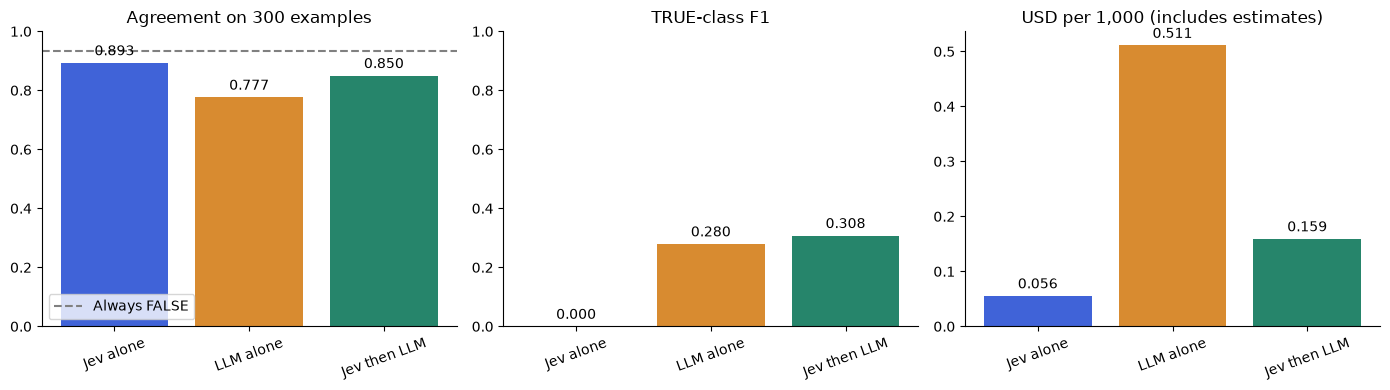

Cascade cost change versus LLM alone (includes estimates): -68.8%
All 600 model responses, including estimates (USD): 0.169953678
Unreported-cost attempts: 600
Estimated-cost attempts: 600
Unknown-cost attempts: 0


In [10]:
plotted = comparison[comparison.method != "Always FALSE"].set_index("method")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ["#4063d8", "#d88b30", "#26856b"]
for ax, field, title in zip(axes, ["accuracy", "f1_TRUE", "cost_per_1000_USD"],
                           ["Agreement on 300 examples", "TRUE-class F1", "USD per 1,000 (includes estimates)"]):
    if field.startswith("cost") and plotted.unknown_cost_attempts.sum():
        ax.text(.5, .5, "Costs incomplete: see table", ha="center")
    else:
        bars = ax.bar(plotted.index, plotted[field], color=colors)
        ax.bar_label(bars, fmt="%.3f", padding=3)
        if field != "cost_per_1000_USD": ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].axhline(comparison.iloc[0].accuracy, color="gray", linestyle="--", label="Always FALSE")
axes[0].legend()
fig.tight_layout()
plt.show()
jev_cost = metrics(rows, jev, "Jev")["cost_usd"]
llm_cost = metrics(rows, llm, "LLM")["cost_usd"]
cascade_cost = metrics(rows, cascade, "Cascade")["cost_usd"]
if not plotted.unknown_cost_attempts.sum() and llm_cost:
    print(f"Cascade cost change versus LLM alone (includes estimates): {(cascade_cost / llm_cost - 1):+.1%}")
else:
    print("Unknown or zero costs: no savings claim.")
all_judges = [*jev.values(), *llm.values()]
print("All 600 model responses, including estimates (USD):", sum(r["cost_usd"] for r in all_judges))
print("Unreported-cost attempts:", sum(r["unreported_cost_attempts"] for r in all_judges))
print("Estimated-cost attempts:", sum(r["estimated_cost_attempts"] for r in all_judges))
print("Unknown-cost attempts:", sum(r["unknown_cost_attempts"] for r in all_judges))

## 7. What the combined approach achieves

At confidence **0.7**, Jev keeps **241 of 300** cases and sends **59** to the LLM.
On the accepted cases, Jev agrees with **96.3%** of the human labels; the LLM agrees
with **87.1%**. Avoiding those LLM calls explains why the combined approach has higher
agreement and an estimated **68.8% lower cost** than asking the LLM on every case.

The combined approach agrees with **85.0%** of all 300 human labels, compared with
**77.7%** for the LLM alone and **89.3%** for Jev alone. Agreement is only part of the
picture: Jev finds **0 of 20** Vague Utterance failures, the LLM finds **13**, and the
combined approach finds **10**. Its TRUE-class F1 is **0.308**, compared with **0.280**
for the LLM and **0** for Jev.

Among the 59 escalated cases, the LLM corrects **11** Jev errors and introduces **24**
new errors. Escalation therefore helps find Vague Utterance failures, but it also adds
false alarms. Low confidence identifies harder cases; it does not guarantee that the
LLM will handle them better overall. Confident Jev mistakes can also bypass the LLM.

The tables below show which errors each approach makes. These results cover 300 labeled
examples, including 20 Vague Utterance failures. Check the policy on new human-reviewed
examples from the intended application before relying on it.

In [11]:
bands = confidence_bands(rows, jev, llm, threshold)
display(pd.DataFrame(bands))
disagreements = []
for r in rows:
    j, l, c = jev[r["id"]], llm[r["id"]], cascade[r["id"]]
    if j["label"] != l["label"] or c["label"] != r["human_label"]:
        disagreements.append({"ID": r["id"], "query": r["user_query"],
            "candidate_intent": r["predicted_intent"], "human": r["human_label"],
            "Jev": j["label"], "confidence": j.get("confidence"), "LLM": l["label"],
            "final": c["label"], "route": c["route"], "LLM_reason": l.get("reason")})
display(pd.DataFrame(disagreements).head(12))
pd.DataFrame(disagreements).to_csv(RUN / "disagreements.csv", index=False)

,group,n,Jev_accuracy,LLM_accuracy,LLM_fixes,LLM_regressions
0,Kept by Jev,241,0.962656,0.871369,3,25
1,Sent to LLM,59,0.610169,0.389831,11,24


,ID,query,candidate_intent,human,Jev,confidence,LLM,final,route,LLM_reason
0,TEST_031,I am busy today,UNSUPPORTED_REQUEST,TRUE,FALSE,0.60,TRUE,TRUE,LLM,The user's statement 'I am busy today' is ambi...
1,TEST_032,I'm not working *this* Saturday.,UNBLOCK_SLOTS,FALSE,FALSE,0.72,TRUE,FALSE,Jev,The user states 'I'm not working *this* Saturd...
2,TEST_034,Free up this weekend,UNBLOCK_SLOTS,FALSE,FALSE,0.82,TRUE,FALSE,Jev,The user query 'Free up this weekend' is ambig...
3,TEST_040,I can work this monday again,IRRELEVANT_QUERY,TRUE,FALSE,0.30,TRUE,TRUE,LLM,The user's statement 'I can work this Monday a...
4,TEST_045,I can work this Monday,IRRELEVANT_QUERY,TRUE,FALSE,0.48,TRUE,TRUE,LLM,The user's statement 'I can work this Monday' ...
5,TEST_046,I can work Monday,IRRELEVANT_QUERY,TRUE,FALSE,0.30,TRUE,TRUE,LLM,The user's statement 'I can work Monday' is am...
6,TEST_085,"I need to block off all of tomorrow, so cancel...",BLOCK_SLOTS,FALSE,FALSE,0.66,TRUE,TRUE,LLM,The user requests to block off all of tomorrow...
7,TEST_086,Clear my 3 PM,UNSUPPORTED_REQUEST,TRUE,FALSE,0.32,TRUE,TRUE,LLM,The user request 'Clear my 3 PM' is ambiguous ...
8,TEST_091,"Let's reschedule, I need to block my calendar",UNSUPPORTED_REQUEST,FALSE,TRUE,0.12,TRUE,TRUE,LLM,The user query contains two conflicting reques...
9,TEST_095,Cancel my 3 PM slot,UNSUPPORTED_REQUEST,TRUE,FALSE,0.76,TRUE,FALSE,Jev,The user request 'Cancel my 3 PM slot' is ambi...


In [12]:
assert len(jev) == len(llm) == len(cascade) == len(rows)
summary = {"dataset_hash": digest(rows), "dataset_source": JUDGE_DATA_SOURCE,
    "policy_hash": digest([POLICY, CRITERIA]),
    "evaluation_ids": [r["id"] for r in rows],
    "threshold": threshold, "threshold_kind": "confidence",
    **client.configuration(),
    "comparison_metrics": [metrics(rows, values, name) for name, values in
                           [("Jev alone", jev), ("LLM alone", llm), ("Jev then LLM", cascade)]]}
if MODE == "replay":
    for field in ("dataset_hash", "dataset_source", "policy_hash", "evaluation_ids",
                  "threshold", "threshold_kind", "comparison_metrics"):
        assert summary[field] == manifest[field], field
    assert client.new_requests == 0
else:
    save_json(RUN / "manifest.json", summary)
    print("Replay this run by setting JUDGE_MODE=replay and JUDGE_EVIDENCE_DIR to", RUN)
save_json(RUN / "summary.json", {**summary, "mode": MODE,
    "comparison": comparison.to_dict("records"), "bands": bands,
    "new_http_attempts": client.new_requests})
print("Notebook completed. Fresh HTTP attempts:", client.new_requests)
print("Outputs:", RUN)
print("Unresolved rows:", comparison.set_index("method")["unresolved"].to_dict())

Notebook completed. Fresh HTTP attempts: 0
Outputs: routing_agent_evals/.runs/judge
Unresolved rows: {'Always FALSE': 0, 'Jev alone': 0, 'LLM alone': 0, 'Jev then LLM': 0}


## Apply the approach to new data

Start with examples labeled using a clear definition of the failure category. Compare
Jev alone, the LLM alone, and the combined approach on the same examples. Count missed
failures and false alarms, and measure cost alongside agreement. Repeat the evaluation
on new examples after changing the model, prompt, or application.

To make a fresh run, select `live`, use a TypeSafe key for Jev and a funded OpenAI
(or OpenRouter) key for the LLM, and choose a new `JUDGE_RUN_DIR`. To replay that run, set
`JUDGE_MODE=replay` and `JUDGE_EVIDENCE_DIR` to the same directory. Changing the model or
prompt changes the request hash. Local run artifacts stay in ignored `.runs/` directories.